In [204]:
# Rain Prediction in Australia 
# weatherAUS.csv is the dataset chosen for predicting the rainfall in Australia
# this dataset was chosen because it had data that suits well for implementing the assignment problem statement. 
# Data samples are huge. All the use cases could be covered, hence this dataset has been chosen

In [205]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)   
RANDOM_SEED = 42                            

In [206]:
# read the dataset , identify the rows n columns , display the first 5 
weather = pd.read_csv(r'weatherAUS.csv')
print('Shape:', weather.shape)
display(weather.head())

Shape: (142193, 24)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


In [207]:
# identify the target , data column that leads to data leakage
target = 'RainTomorrow'
leak_column = 'RISK_MM'

numeric_columns = weather.select_dtypes(include='number').columns.drop(leak_column).tolist()
categorical_columns = weather.select_dtypes(exclude='number').columns.drop([target, 'Date']).tolist()

print(f'Numeric features ({len(numeric_columns)}):', numeric_columns)
print(f'\nCategorical features ({len(categorical_columns)}):', categorical_columns)
print(f'Leakage column that needs to be dropped: {leak_column}')
print(f'Target: {target}')

Numeric features (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

Categorical features (5): ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
Leakage column that needs to be dropped: RISK_MM
Target: RainTomorrow


In [208]:
# Kind of each feature (based on what the column means)
feature_kind = {}
for col in numeric_columns:
    feature_kind[col] = 'Numeric – continuous'
feature_kind['Cloud9am'] = 'Numeric – ordinal (0–8 oktas)'
feature_kind['Cloud3pm'] = 'Numeric – ordinal (0–8 oktas)'
for col in ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']:
    feature_kind[col] = 'Categorical – nominal'
feature_kind['RainToday'] = 'Categorical – binary'
feature_kind['Date'] = 'Date (converted to Month)'
feature_kind[leak_column] = 'Leakage – dropped'
feature_kind[target] = 'Target – binary'

# Build the table
feature_types = pd.DataFrame({
    'Data Type': weather.dtypes.astype(str),
    'Feature Kind': pd.Series(feature_kind),
    'Unique Values': weather.nunique(),
    'Missing %': (weather.isnull().mean() * 100).round(2),
    'Example': weather.iloc[0]
})
feature_types

,Data Type,Feature Kind,Unique Values,Missing %,Example
Cloud3pm,float64,Numeric – ordinal (0–8 oktas),10,40.15,NaN
Cloud9am,float64,Numeric – ordinal (0–8 oktas),10,37.74,8.0
Date,str,Date (converted to Month),3436,0.00,2008-12-01
Evaporation,float64,Numeric – continuous,356,42.79,NaN
Humidity3pm,float64,Numeric – continuous,101,2.54,22.0
Humidity9am,float64,Numeric – continuous,101,1.25,71.0
Location,str,Categorical – nominal,49,0.00,Albury
MaxTemp,float64,Numeric – continuous,505,0.23,22.9
MinTemp,float64,Numeric – continuous,389,0.45,13.4
Pressure3pm,float64,Numeric – continuous,549,9.83,1007.1


RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64
RainTomorrow
No     77.581878
Yes    22.418122
Name: proportion, dtype: float64


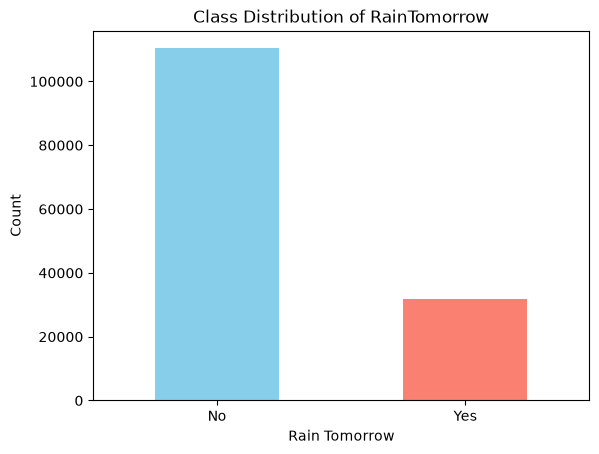

In [209]:
# Count and percentage of each class
print(weather[target].value_counts())
print(weather[target].value_counts(normalize=True) * 100)

# Bar chart
weather[target].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Class Distribution of RainTomorrow')
plt.xlabel('Rain Tomorrow')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [210]:
# Step 2: Data Preprocessing

In [211]:
# Count and percentage of missing values per column
missing_count = weather.isnull().sum()
missing_percent = weather.isnull().mean() * 100

missing_table = pd.DataFrame({'Missing Count': missing_count,
                              'Missing %': missing_percent.round(2)})
missing_table = missing_table[missing_table['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing_table)

               Missing Count  Missing %
Sunshine               67816      47.69
Evaporation            60843      42.79
Cloud3pm               57094      40.15
Cloud9am               53657      37.74
Pressure9am            14014       9.86
Pressure3pm            13981       9.83
WindDir9am             10013       7.04
WindGustDir             9330       6.56
WindGustSpeed           9270       6.52
WindDir3pm              3778       2.66
Humidity3pm             3610       2.54
Temp3pm                 2726       1.92
WindSpeed3pm            2630       1.85
Humidity9am             1774       1.25
Rainfall                1406       0.99
RainToday               1406       0.99
WindSpeed9am            1348       0.95
Temp9am                  904       0.64
MinTemp                  637       0.45
MaxTemp                  322       0.23


In [212]:
# Exact duplicate rows
duplicate_rows = weather.duplicated().sum()
print('Exact duplicate rows:', duplicate_rows)

# Same location recorded more than once on the same date
duplicate_date_location = weather.duplicated(subset=['Date', 'Location']).sum()
print('Duplicate (Date, Location) rows:', duplicate_date_location)

# Remove duplicates if any are found
if duplicate_rows > 0:
    weather = weather.drop_duplicates()
    print('Duplicates removed. New shape:', weather.shape)
else:
    print('No duplicates found – no rows removed.')

Exact duplicate rows: 0
Duplicate (Date, Location) rows: 0
No duplicates found – no rows removed.


In [213]:
# Drop the leakage column
weather = weather.drop(columns=[leak_column])

# Convert Date to Month, then drop Date
weather['Month'] = pd.to_datetime(weather['Date']).dt.month
weather = weather.drop(columns=['Date'])

# Encode the target: No = 0, Yes = 1
weather[target] = weather[target].map({'No': 0, 'Yes': 1})

print(weather.shape)

(142193, 23)


In [214]:
# Split and scale
from sklearn.model_selection import train_test_split

X = weather.drop(columns=[target])
y = weather[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Rain % in train:', round(y_train.mean() * 100, 2), ' test:', round(y_test.mean() * 100, 2))

Train: (113754, 22)  Test: (28439, 22)
Rain % in train: 22.42  test: 22.42


In [215]:
from sklearn.impute import SimpleImputer

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[categorical_columns] = cat_imputer.fit_transform(X_train[categorical_columns])
X_test[categorical_columns] = cat_imputer.transform(X_test[categorical_columns])

In [216]:
from sklearn.preprocessing import OneHotEncoder

# Binary column → 0/1
X_train['RainToday'] = X_train['RainToday'].map({'No': 0, 'Yes': 1})
X_test['RainToday'] = X_test['RainToday'].map({'No': 0, 'Yes': 1})

# Nominal columns → one-hot
nominal_columns = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = pd.DataFrame(encoder.fit_transform(X_train[nominal_columns]),
                             columns=encoder.get_feature_names_out(nominal_columns),
                             index=X_train.index)
test_encoded = pd.DataFrame(encoder.transform(X_test[nominal_columns]),
                            columns=encoder.get_feature_names_out(nominal_columns),
                            index=X_test.index)

X_train = pd.concat([X_train.drop(columns=nominal_columns), train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=nominal_columns), test_encoded], axis=1)

print('Train:', X_train.shape, ' Test:', X_test.shape)
X_train.head()

Train: (113754, 115)  Test: (28439, 115)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Month,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
101064,19.3,34.8,0.0,13.8,12.5,56.0,15.0,7.0,52.0,20.0,1013.4,1010.6,3.0,3.0,24.3,33.6,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
18241,NaN,NaN,0.2,NaN,NaN,39.0,11.0,22.0,NaN,NaN,1020.5,1019.0,NaN,NaN,NaN,NaN,0,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
96741,13.0,23.4,0.0,NaN,NaN,43.0,2.0,22.0,64.0,44.0,1012.5,1010.4,NaN,NaN,16.4,23.1,0,11,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
139785,25.0,33.4,0.0,5.8,NaN,63.0,19.0,26.0,75.0,54.0,1004.3,1001.2,6.0,4.0,29.4,33.0,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
83246,15.3,25.8,0.0,8.0,11.7,30.0,9.0,13.0,58.0,45.0,1024.9,1021.2,7.0,2.0,21.3,24.2,0,11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.

In [217]:
num_imputer = SimpleImputer(strategy='median')
X_train[numeric_columns] = num_imputer.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = num_imputer.transform(X_test[numeric_columns])

print('Missing values left – train:', X_train.isnull().sum().sum(),
      ' test:', X_test.isnull().sum().sum())

Missing values left – train: 0  test: 0


In [218]:
from sklearn.preprocessing import StandardScaler

scale_columns = numeric_columns + ['Month']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_columns] = scaler.fit_transform(X_train[scale_columns])
X_test_scaled[scale_columns] = scaler.transform(X_test[scale_columns])

print('Train:', X_train_scaled.shape, ' Test:', X_test_scaled.shape)
X_train_scaled[scale_columns].describe().loc[['mean', 'std']].round(2)

Train: (113754, 115)  Test: (28439, 115)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Month
mean,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [219]:
# models

In [220]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

trained_models = {}      # model name → fitted model
predictions = {}         # model name → predicted labels (0/1)
probabilities = {}       # model name → predicted probability of rain (needed for AUC)

In [221]:
# logistic regression

In [222]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
log_reg.fit(X_train_scaled, y_train)

trained_models['Logistic Regression'] = log_reg
predictions['Logistic Regression'] = log_reg.predict(X_test_scaled)
probabilities['Logistic Regression'] = log_reg.predict_proba(X_test_scaled)[:, 1]
print('Logistic Regression trained')

Logistic Regression trained


In [223]:
# Decision tree

In [224]:
dec_tree = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_SEED)
dec_tree.fit(X_train_scaled, y_train)

trained_models['Decision Tree'] = dec_tree
predictions['Decision Tree'] = dec_tree.predict(X_test_scaled)
probabilities['Decision Tree'] = dec_tree.predict_proba(X_test_scaled)[:, 1]
print('Decision Tree trained')

Decision Tree trained


In [225]:
# k-NN

In [226]:
knn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

trained_models['kNN'] = knn
predictions['kNN'] = knn.predict(X_test_scaled)
probabilities['kNN'] = knn.predict_proba(X_test_scaled)[:, 1]
print('kNN trained')

kNN trained


In [227]:
# Naive bayes - guassian

In [228]:
naive_bayes = GaussianNB()
naive_bayes.fit(X_train_scaled, y_train)

trained_models['Naive Bayes'] = naive_bayes
predictions['Naive Bayes'] = naive_bayes.predict(X_test_scaled)
probabilities['Naive Bayes'] = naive_bayes.predict_proba(X_test_scaled)[:, 1]
print('Naive Bayes trained')

Naive Bayes trained


In [229]:
# Random forest 

In [230]:
rand_forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
rand_forest.fit(X_train_scaled, y_train)

trained_models['Random Forest'] = rand_forest
predictions['Random Forest'] = rand_forest.predict(X_test_scaled)
probabilities['Random Forest'] = rand_forest.predict_proba(X_test_scaled)[:, 1]
print('Random Forest trained')

Random Forest trained


In [231]:
# metrics

In [232]:
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, roc_curve)

In [233]:
results = []

for model_name in trained_models:
    y_pred = predictions[model_name]
    y_prob = probabilities[model_name]

    results.append({
        'ML Model Name': model_name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'AUC':       roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'MCC':       matthews_corrcoef(y_test, y_pred)
    })

metrics_table = pd.DataFrame(results).set_index('ML Model Name').round(4)
metrics_table

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8493,0.8721,0.7341,0.5140,0.6047,0.5276
Decision Tree,0.8406,0.8454,0.7219,0.4698,0.5692,0.4932
kNN,0.8499,0.8687,0.7662,0.4756,0.5869,0.5226
Naive Bayes,0.6515,0.7461,0.3609,0.7195,0.4807,0.2948
Random Forest,0.8572,0.8880,0.7847,0.5002,0.6110,0.5488


In [234]:
# visualization

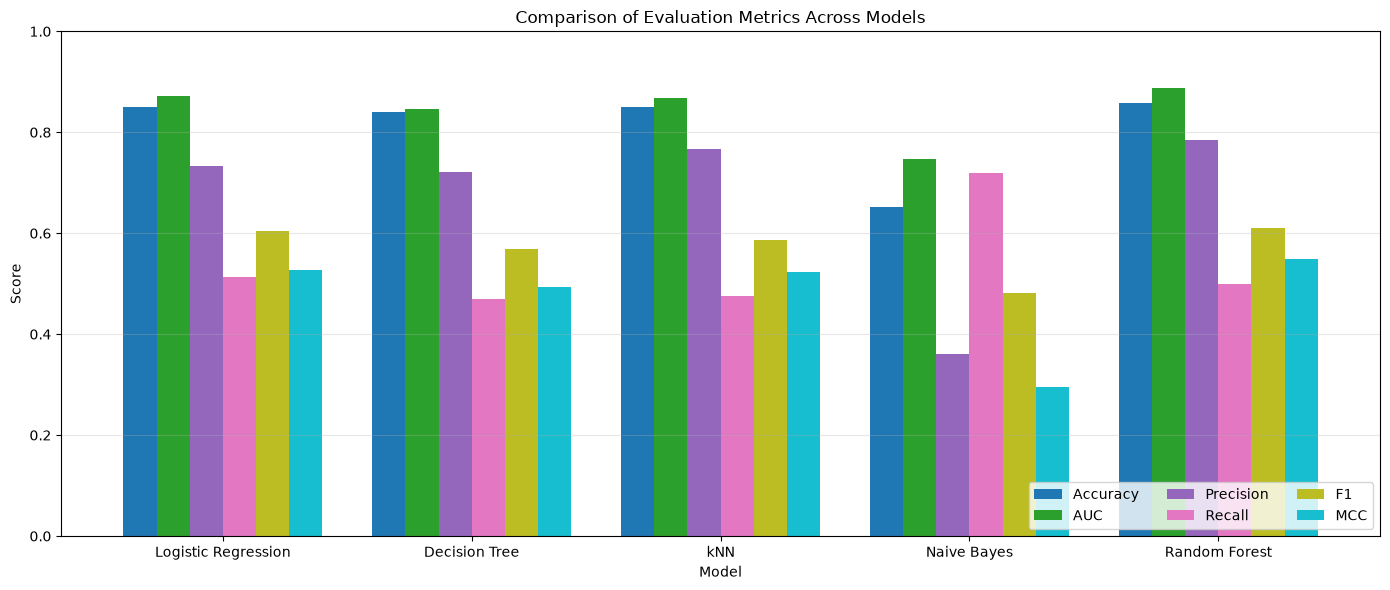

In [235]:
metrics_table.plot(kind='bar', figsize=(14, 6), width=0.8, colormap='tab10')
plt.title('Comparison of Evaluation Metrics Across Models')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right', ncol=3)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

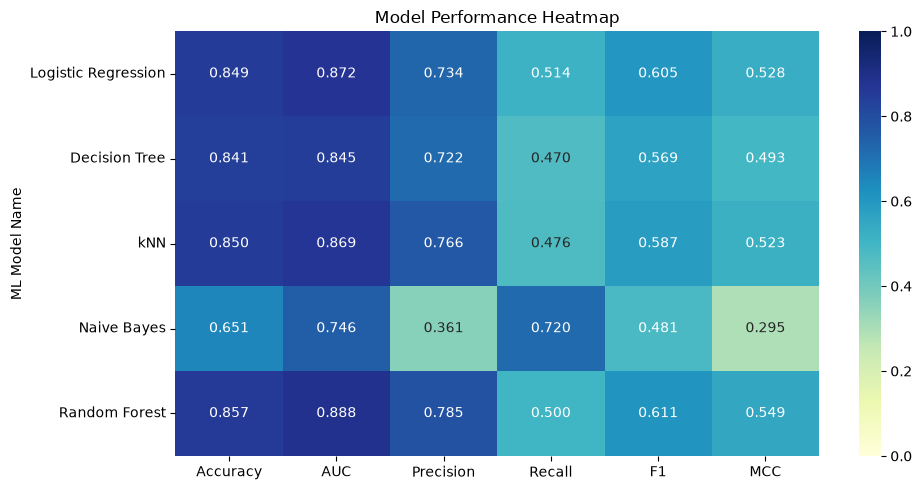

In [236]:
plt.figure(figsize=(10, 5))
sns.heatmap(metrics_table, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Model Performance Heatmap')
plt.tight_layout()
plt.show()

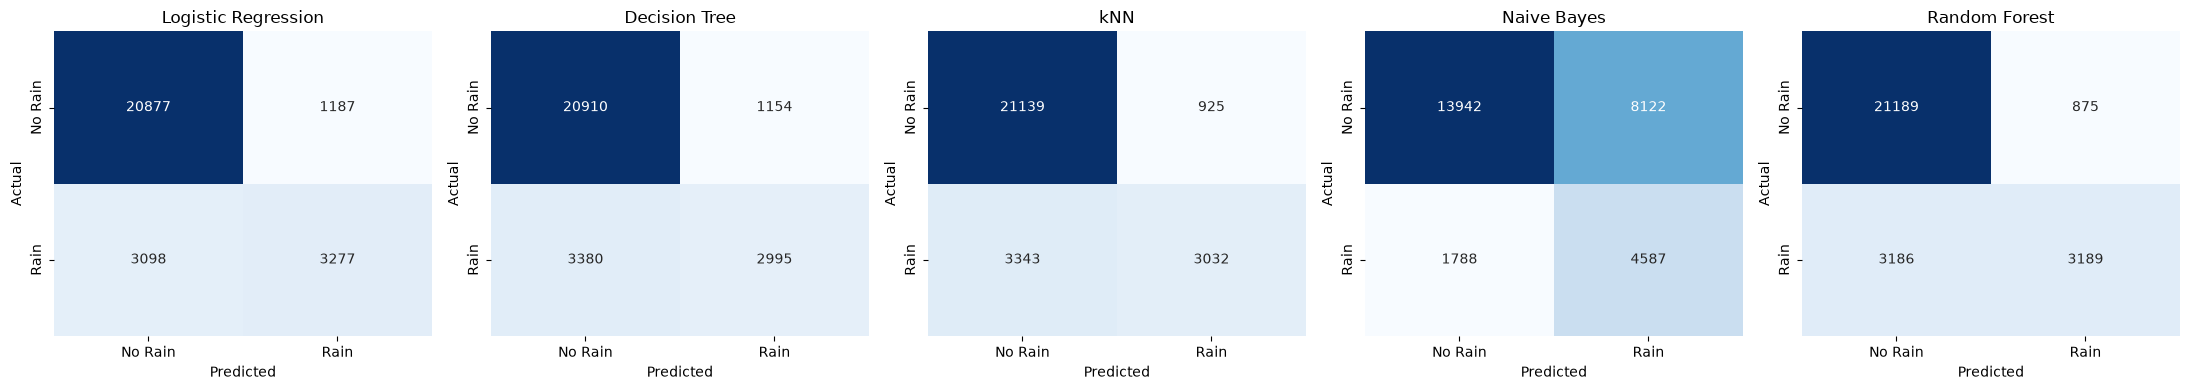

In [237]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, model_name in zip(axes, trained_models):
    cm = confusion_matrix(y_test, predictions[model_name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Rain', 'Rain'], yticklabels=['No Rain', 'Rain'])
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

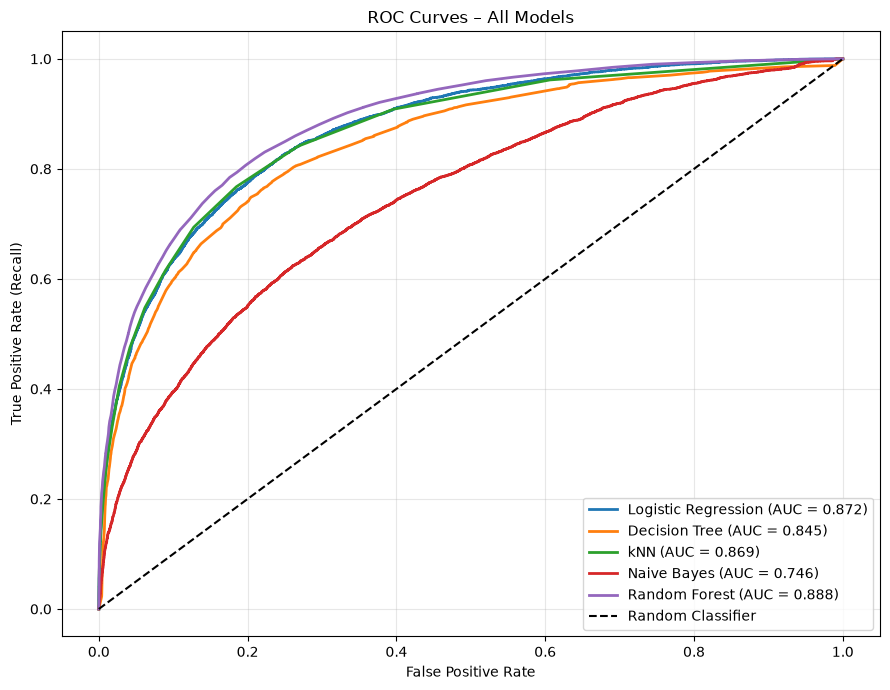

In [238]:
plt.figure(figsize=(9, 7))

for model_name in trained_models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[model_name])
    plt.plot(fpr, tpr, linewidth=2,
             label=f"{model_name} (AUC = {metrics_table.loc[model_name, 'AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves – All Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [239]:
print('Best model for each metric:')
for metric in metrics_table.columns:
    best = metrics_table[metric].idxmax()
    print(f'  {metric:10s}: {best} ({metrics_table.loc[best, metric]:.4f})')

Best model for each metric:
  Accuracy  : Random Forest (0.8572)
  AUC       : Random Forest (0.8880)
  Precision : Random Forest (0.7847)
  Recall    : Naive Bayes (0.7195)
  F1        : Random Forest (0.6110)
  MCC       : Random Forest (0.5488)
